<module 'matplotlib.pyplot' from '/Users/yanrui/Developer/CSCourses/csci3151/.venv/lib/python3.15/site-packages/matplotlib/pyplot.py'>

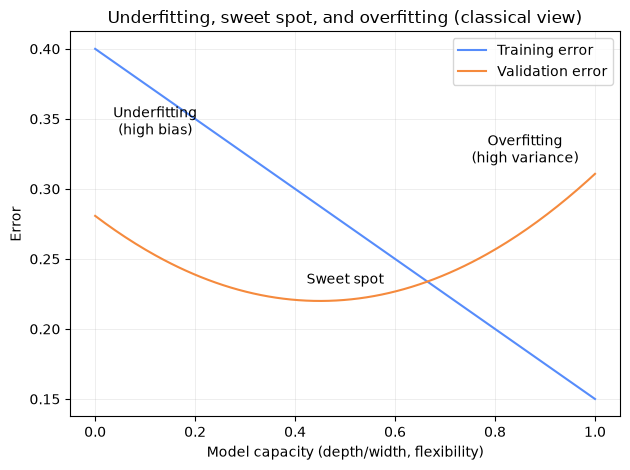

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Synthetic "capacity" axis
capacity = np.linspace(0, 1, 200)

# Toy curves:
# - training error decreases with capacity
# - validation error has a U-shape
train_error = 0.40 - 0.25 * capacity
val_error   = 0.22 + 0.30 * (capacity - 0.45) ** 2

fig, ax = plt.subplots()

ax.plot(capacity, train_error, label="Training error")
ax.plot(capacity, val_error,   label="Validation error")

ax.set_xlabel("Model capacity (depth/width, flexibility)")
ax.set_ylabel("Error")
ax.set_title("Underfitting, sweet spot, and overfitting (classical view)")
ax.legend()
ax.grid(True, alpha=0.3)

# Annotate regions (roughly)
ax.text(0.12, 0.36, "Underfitting\n(high bias)",
        ha="center", va="top")
ax.text(0.50, 0.23, "Sweet spot",
        ha="center", va="bottom")
ax.text(0.86, 0.34, "Overfitting\n(high variance)",
        ha="center", va="top")

plt.tight_layout()
plt

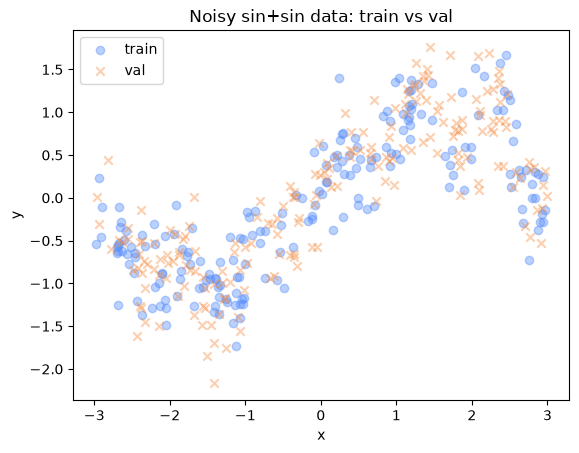

In [5]:
# Generate data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(3151)

def make_sine_data(n=200):
    x = rng.uniform(-3.0, 3.0, size=(n, 1))
    noise = rng.normal(0.0, 0.35, size=(n, 1))
    y = np.sin(x) + noise + 0.25*np.sin(6*x)
    return x.astype(np.float32), y.astype(np.float32)

X_train, y_train = make_sine_data(200)
X_val,   y_val   = make_sine_data(200)

fig, ax = plt.subplots()
ax.scatter(X_train, y_train, alpha=0.4, label="train")
ax.scatter(X_val, y_val, alpha=0.4, marker="x", label="val")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Noisy sin+sin data: train vs val")
ax.legend()

In [6]:
# Small vs less-small MLPs
# We’ll use PyTorch to define two models:

# device = "cuda" if torch.cuda.is_available() else "cpu" tells PyTorch to run on the GPU, if it is available
# large = LargeMLP().to(device) puts the NN on the device.
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds   = TensorDataset(torch.from_numpy(X_val),   torch.from_numpy(y_val))

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=64, shuffle=False)

# Small MLP: 1 hidden layer with 16 units.
class SmallMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.net(x)

# Large MLP: 3 hidden layers with 128 units each.
class LargeMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        return self.net(x)

small = SmallMLP().to(device)
large = LargeMLP().to(device)

sum(p.numel() for p in small.parameters()), sum(p.numel() for p in large.parameters())

(49, 33409)

In [7]:
# Training loop
def train_model(model, train_loader, val_loader, epochs=200, lr=1e-3):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    history = {"epoch": [], "train_mse": [], "val_mse": []}

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        n_train = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            preds = model(xb)
            loss = loss_fn(preds, yb)
            loss.backward()
            opt.step()
            train_loss += loss.item() * xb.size(0)
            n_train += xb.size(0)

        model.eval()
        val_loss = 0.0
        n_val = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                preds = model(xb)
                loss = loss_fn(preds, yb)
                val_loss += loss.item() * xb.size(0)
                n_val += xb.size(0)

        history["epoch"].append(epoch)
        history["train_mse"].append(train_loss / n_train)
        history["val_mse"].append(val_loss / n_val)

    return pd.DataFrame(history)

hist_small = train_model(small, train_loader, val_loader, epochs=200, lr=1e-3)
hist_large = train_model(large, train_loader, val_loader, epochs=200, lr=1e-3)

hist_small.tail(3), hist_large.tail(3)

(     epoch  train_mse   val_mse
 197    198   0.163330  0.198205
 198    199   0.162962  0.195744
 199    200   0.162052  0.193941,
      epoch  train_mse   val_mse
 197    198   0.133528  0.151326
 198    199   0.117303  0.148327
 199    200   0.115028  0.145597)

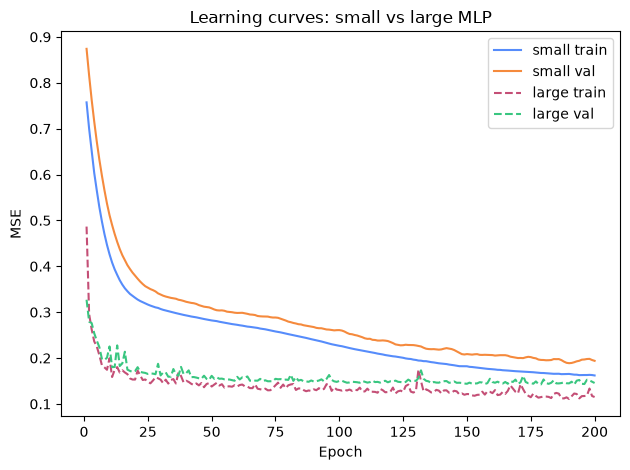

In [8]:
# Learning curves
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot(hist_small["epoch"], hist_small["train_mse"], label="small train")
ax.plot(hist_small["epoch"], hist_small["val_mse"],   label="small val")
ax.plot(hist_large["epoch"], hist_large["train_mse"], label="large train", linestyle="--")
ax.plot(hist_large["epoch"], hist_large["val_mse"],   label="large val", linestyle="--")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.set_title("Learning curves: small vs large MLP")
ax.legend()
plt.tight_layout()

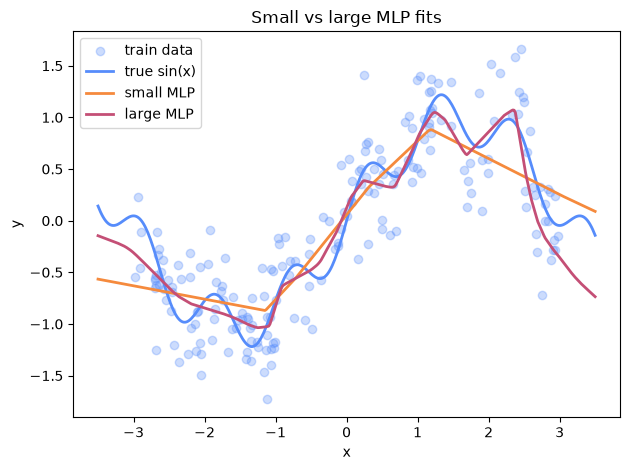

In [9]:
xs = np.linspace(-3.5, 3.5, 400, dtype=np.float32).reshape(-1, 1)
xs_t = torch.from_numpy(xs).to(device)

small.eval()
large.eval()
with torch.no_grad():
    ys_small = small(xs_t).cpu().numpy()
    ys_large = large(xs_t).cpu().numpy()

fig, ax = plt.subplots()
ax.scatter(X_train, y_train, alpha=0.3, label="train data")
ax.plot(xs, np.sin(xs) + 0.25*np.sin(6.0*xs), label="true sin(x)", linewidth=2)
ax.plot(xs, ys_small, label="small MLP", linewidth=2)
ax.plot(xs, ys_large, label="large MLP", linewidth=2)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Small vs large MLP fits")
ax.legend()
plt.tight_layout()

In [10]:
summary_ex1 = pd.DataFrame({
    "model": ["small MLP", "large MLP"],
    "params": [
        sum(p.numel() for p in small.parameters()),
        sum(p.numel() for p in large.parameters())
    ],
    "final_train_mse": [hist_small["train_mse"].iloc[-1],
                        hist_large["train_mse"].iloc[-1]],
    "final_val_mse":   [hist_small["val_mse"].iloc[-1],
                        hist_large["val_mse"].iloc[-1]],
})
summary_ex1

,model,params,final_train_mse,final_val_mse
0,small MLP,49,0.162052,0.193941
1,large MLP,33409,0.115028,0.145597


In [11]:
# Deep classification & generalization gap
# Now a classification example closer to the rest of the course:
#
# Goal:
#
# Train MLP classifiers with different capacities on the scikit-learn digits dataset.
# Compare:
# Train vs validation accuracy (generalization gap).
# Confusion matrices / errors.
# Dataset:
#
# scikit-learn load_digits() (~1,800 8×8 digit images).
# We’ll use a simple train / validation split.
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

digits = load_digits()
X = digits.data
y = digits.target

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, random_state=3151, stratify=y
)

X_train.shape, X_val.shape

((1257, 64), (540, 64))

In [12]:
# Small vs less-small MLP classifiers
def make_mlp(hidden_layer_sizes, alpha=1e-4, max_iter=200):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=hidden_layer_sizes,
            activation="relu",
            alpha=alpha,
            max_iter=max_iter,
            random_state=3151
        ))
    ])

models_ex2 = {
    "small-mlp": make_mlp((32,)),
    "medium-mlp": make_mlp((128,)),
    "large-mlp": make_mlp((512, 512))
}

results_ex2 = []
for name, model in models_ex2.items():
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_val   = model.predict(X_val)
    train_acc = accuracy_score(y_train, y_pred_train)
    val_acc   = accuracy_score(y_val,   y_pred_val)
    results_ex2.append({
        "model": name,
        "hidden_layers": str(model.named_steps["mlp"].hidden_layer_sizes),
        "train_acc": train_acc,
        "val_acc": val_acc,
        "gap_acc": train_acc - val_acc
    })

results_ex2_df = pd.DataFrame(results_ex2)
results_ex2_df

/Users/yanrui/Developer/CSCourses/csci3151/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,hidden_layers,train_acc,val_acc,gap_acc
0,small-mlp,"(32,)",1.0,0.962963,0.037037
1,medium-mlp,"(128,)",1.0,0.972222,0.027778
2,large-mlp,"(512, 512)",1.0,0.975926,0.024074


In [13]:
results_ex2_df

,model,hidden_layers,train_acc,val_acc,gap_acc
0,small-mlp,"(32,)",1.0,0.962963,0.037037
1,medium-mlp,"(128,)",1.0,0.972222,0.027778
2,large-mlp,"(512, 512)",1.0,0.975926,0.024074
